**Importing libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor,StackingRegressor
from sklearn.model_selection import cross_val_score,RandomizedSearchCV,GridSearchCV,TimeSeriesSplit
from sklearn.preprocessing import StandardScaler,OrdinalEncoder
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from sklearn.metrics import mean_absolute_error,mean_absolute_percentage_error,mean_squared_error,root_mean_squared_error,r2_score

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Unzipping the dataset file**

In [3]:
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/Colab Notebooks/داده-محور سوم.zip') as zip:
  zip.extractall('dataset_3')


In [4]:
data = pd.read_excel('/content/dataset_3/╪»╪º╪»┘ç-┘à╪¡┘ê╪▒ ╪│┘ê┘à/╪┤╪º╪«╪╡ ╪│╪º╪╣╪¬█î 1397-1404.xlsx',skiprows=1)
data.head()
# data.shape



,استان,منطقه,ایستگاه,تاریخ,زمان,CO,O3,NO2,SO2,PM10,PM2_5,AQI,آلاینده,وضعیت شاخص
0,اصفهان,اصفهان,شهر اصفهان,1397/01/01,00:00:00,20.0,22.0,9.0,44.0,NaN,72,72,PM 2.5,قابل قبول
1,اصفهان,اصفهان,شهر اصفهان,1397/01/01,01:00:00,20.0,22.0,9.0,44.0,NaN,72,72,PM 2.5,قابل قبول
2,اصفهان,اصفهان,شهر اصفهان,1397/01/01,02:00:00,21.0,22.0,9.0,44.0,NaN,73,73,PM 2.5,قابل قبول
3,اصفهان,اصفهان,شهر اصفهان,1397/01/01,03:00:00,21.0,22.0,9.0,45.0,NaN,72,72,PM 2.5,قابل قبول
4,اصفهان,اصفهان,شهر اصفهان,1397/01/01,04:00:00,22.0,22.0,9.0,45.0,NaN,72,72,PM 2.5,قابل قبول


In [5]:
!pip install persiantools

**check data**

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70128 entries, 0 to 70127
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   استان       70128 non-null  object 
 1   منطقه       70128 non-null  object 
 2   ایستگاه     70128 non-null  object 
 3   تاریخ       70128 non-null  object 
 4   زمان        70128 non-null  object 
 5   CO          69745 non-null  float64
 6   O3          60861 non-null  float64
 7   NO2         66699 non-null  float64
 8   SO2         69748 non-null  float64
 9   PM10        25741 non-null  float64
 10  PM2_5       70128 non-null  int64  
 11  AQI         70128 non-null  int64  
 12  آلاینده     70128 non-null  object 
 13  وضعیت شاخص  70128 non-null  object 
dtypes: float64(5), int64(2), object(7)
memory usage: 7.5+ MB


**preprocessing**

In [7]:
from persiantools.jdatetime import JalaliDateTime
data['datetime_shamsi']=data['تاریخ'] + ' ' + data['زمان']
data['datetime'] = data['datetime_shamsi'].apply(
    lambda x: JalaliDateTime.strptime(x, '%Y/%m/%d %H:%M:%S').to_gregorian()
)


In [8]:
data.drop(columns=['datetime_shamsi','تاریخ','زمان','ایستگاه','منطقه','استان','PM10'],inplace=True)
data.head()

,CO,O3,NO2,SO2,PM2_5,AQI,آلاینده,وضعیت شاخص,datetime
0,20.0,22.0,9.0,44.0,72,72,PM 2.5,قابل قبول,2018-03-21 00:00:00
1,20.0,22.0,9.0,44.0,72,72,PM 2.5,قابل قبول,2018-03-21 01:00:00
2,21.0,22.0,9.0,44.0,73,73,PM 2.5,قابل قبول,2018-03-21 02:00:00
3,21.0,22.0,9.0,45.0,72,72,PM 2.5,قابل قبول,2018-03-21 03:00:00
4,22.0,22.0,9.0,45.0,72,72,PM 2.5,قابل قبول,2018-03-21 04:00:00


In [9]:
data.set_index('datetime',inplace=True)
data.sort_index(inplace=True)
data.head()

,CO,O3,NO2,SO2,PM2_5,AQI,آلاینده,وضعیت شاخص
datetime,,,,,,,,
2018-03-21 00:00:00,20.0,22.0,9.0,44.0,72,72,PM 2.5,قابل قبول
2018-03-21 01:00:00,20.0,22.0,9.0,44.0,72,72,PM 2.5,قابل قبول
2018-03-21 02:00:00,21.0,22.0,9.0,44.0,73,73,PM 2.5,قابل قبول
2018-03-21 03:00:00,21.0,22.0,9.0,45.0,72,72,PM 2.5,قابل قبول
2018-03-21 04:00:00,22.0,22.0,9.0,45.0,72,72,PM 2.5,قابل قبول


In [10]:
num_col=data.select_dtypes(include=[np.number]).columns
data[num_col].corr(method='spearman')

,CO,O3,NO2,SO2,PM2_5,AQI
CO,1.000000,-0.290720,0.177872,0.381652,0.360400,0.172019
O3,-0.290720,1.000000,0.159774,-0.257829,-0.082648,0.355802
NO2,0.177872,0.159774,1.000000,-0.265152,0.368104,0.428507
SO2,0.381652,-0.257829,-0.265152,1.000000,0.166082,0.031395
PM2_5,0.360400,-0.082648,0.368104,0.166082,1.000000,0.769377
AQI,0.172019,0.355802,0.428507,0.031395,0.769377,1.000000


In [11]:
data['آلاینده'].value_counts()
vals = ['O3,PM 10,PM 2.5', 'O3,NO2,PM 2.5', 'O3,NO2', 'CO', 'O3,PM 10']
data = data.drop(data[data['آلاینده'].isin(vals)].index, axis=0)

In [12]:
o = OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
for i in data.columns:
  if data[i].dtype == 'object':
    data[i]=o.fit_transform(data[[i]])

data.head()

,CO,O3,NO2,SO2,PM2_5,AQI,آلاینده,وضعیت شاخص
datetime,,,,,,,,
2018-03-21 00:00:00,20.0,22.0,9.0,44.0,72,72,6.0,2.0
2018-03-21 01:00:00,20.0,22.0,9.0,44.0,72,72,6.0,2.0
2018-03-21 02:00:00,21.0,22.0,9.0,44.0,73,73,6.0,2.0
2018-03-21 03:00:00,21.0,22.0,9.0,45.0,72,72,6.0,2.0
2018-03-21 04:00:00,22.0,22.0,9.0,45.0,72,72,6.0,2.0


In [13]:
num_col=data.select_dtypes(include=[np.number]).columns
data[num_col]=data[num_col].interpolate(method='linear')
data[num_col]=data[num_col].ffill().bfill()

**Visualization**

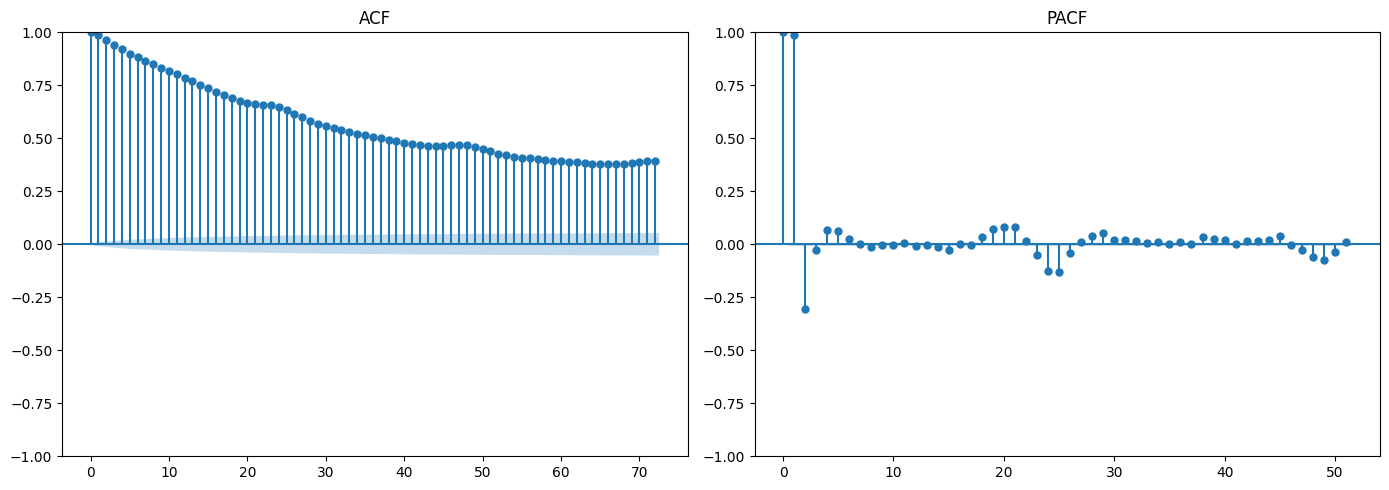

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(data['AQI'], lags=72, ax=ax[0])
plot_pacf(data['AQI'], lags=51, ax=ax[1], method='ywm')

ax[0].set_title('ACF')
ax[1].set_title('PACF')

plt.tight_layout()
plt.show()

****Feature Engineering****

In [15]:
data['AQI_1']=data['AQI'].shift(1)
data['AQI_2']=data['AQI'].shift(2)
data['AQI_3']=data['AQI'].shift(3)
data['AQI_12']=data['AQI'].shift(12)
data['AQI_24']=data['AQI'].shift(24)
data['AQI_48']=data['AQI'].shift(48)
data['AQI_72']=data['AQI'].shift(72)
data['AQI_168']=data['AQI'].shift(168)

data['آلاینده1']=data['آلاینده'].shift(1)
data['وضعیت شاخص 1']=data['وضعیت شاخص'].shift(1)
data = data.drop(columns=['آلاینده','وضعیت شاخص'])

data['SO2_24']=data['SO2'].shift(24)
data['cO_24']=data['CO'].shift(24)


In [16]:
for i in [12,24,168,720]:
  data[f'AQI_mean{i}']=data['AQI'].shift(1).rolling(window=i).mean()
  data[f'AQI_std{i}']=data['AQI'].shift(1).rolling(window=i).std()
  data[f'AQI_min{i}']=data['AQI'].shift(1).rolling(window=i).min()
  data[f'AQI_max{i}']=data['AQI'].shift(1).rolling(window=i).max()


data['ewm_24'] = data['AQI'].shift(1).ewm(span=24).mean()
data['ewm_168'] = data['AQI'].shift(1).ewm(span=168).mean()

In [17]:
data['year']       = data.index.year
data['month']      = data.index.month
data['day']        = data.index.day
data['dayofweek']  = data.index.dayofweek
data['hour']       = data.index.hour
data['quarter']    = data.index.quarter
data['weekofyear'] = data.index.isocalendar().week
data['dayofyear']    = data.index.dayofyear

In [18]:
data['month_sin']=np.sin(2 * np.pi * data['month'] / 12)
data['month_cos']=np.cos(2 * np.pi * data['month'] / 12)

data['dayofweek_sin']=np.sin(2 * np.pi * data['dayofweek'] / 7)
data['dayofweek_cos']=np.cos(2 * np.pi * data['dayofweek'] / 7)

data['dayofyear_sin']=np.sin(2 * np.pi * data['dayofyear'] / 365)
data['dayofyear_cos']=np.cos(2 * np.pi * data['dayofyear'] / 365)

data['hour_sin']=np.sin(2 * np.pi * data['hour'] / 24)
data['hour_cos']=np.cos(2 * np.pi * data['hour'] / 24)

data = data.drop(columns=['dayofweek','month','hour'])

In [19]:
data.dropna(inplace=True)

In [20]:
data.shape

(69394, 49)

In [21]:
data.head(10)

,CO,O3,NO2,SO2,PM2_5,AQI,AQI_1,AQI_2,AQI_3,AQI_12,AQI_24,AQI_48,AQI_72,AQI_168,آلاینده1,وضعیت شاخص 1,SO2_24,cO_24,AQI_mean12,AQI_std12,AQI_min12,AQI_max12,AQI_mean24,AQI_std24,AQI_min24,AQI_max24,AQI_mean168,AQI_std168,AQI_min168,AQI_max168,AQI_mean720,AQI_std720,AQI_min720,AQI_max720,ewm_24,ewm_168,year,day,quarter,weekofyear,dayofyear,month_sin,month_cos,dayofweek_sin,dayofweek_cos,dayofyear_sin,dayofyear_cos,hour_sin,hour_cos
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2018-04-20 00:00:00,45.0,19.0,8.0,42.0,64,64,63.0,62.0,60.0,69.0,82.0,60.0,70.0,63.0,6.0,2.0,69.0,36.0,60.750000,3.137022,58.0,69.0,68.750000,9.114012,58.0,82.0,70.678571,8.267476,55.0,102.0,79.147222,14.888851,55.0,147.0,66.133962,70.752327,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.000000,1.000000e+00
2018-04-20 01:00:00,49.0,19.0,8.0,42.0,66,66,64.0,63.0,62.0,63.0,81.0,62.0,91.0,62.0,6.0,2.0,69.0,36.0,60.333333,2.103388,58.0,64.0,68.000000,8.707818,58.0,81.0,70.684524,8.262273,55.0,102.0,79.136111,14.897175,55.0,147.0,65.963245,70.672403,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.258819,9.659258e-01
2018-04-20 02:00:00,53.0,19.0,7.0,43.0,68,68,66.0,64.0,63.0,60.0,81.0,63.0,68.0,65.0,6.0,2.0,69.0,37.0,60.583333,2.574643,58.0,66.0,67.375000,8.261027,58.0,81.0,70.708333,8.242837,55.0,102.0,79.127778,14.902849,55.0,147.0,65.966186,70.617098,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.500000,8.660254e-01
2018-04-20 03:00:00,56.0,19.0,7.0,44.0,71,71,68.0,66.0,64.0,59.0,81.0,64.0,67.0,64.0,6.0,2.0,69.0,37.0,61.250000,3.333712,58.0,68.0,66.833333,7.738479,58.0,81.0,70.726190,8.233641,55.0,102.0,79.120833,14.906873,55.0,147.0,66.128891,70.586120,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.707107,7.071068e-01
2018-04-20 04:00:00,57.0,19.0,7.0,44.0,76,76,71.0,68.0,66.0,59.0,81.0,65.0,66.0,63.0,6.0,2.0,69.0,37.0,62.250000,4.266679,58.0,71.0,66.416667,7.192488,58.0,81.0,70.767857,8.217094,55.0,102.0,79.119444,14.907584,55.0,147.0,66.518580,70.591019,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.866025,5.000000e-01
2018-04-20 05:00:00,58.0,19.0,7.0,41.0,81,81,76.0,71.0,68.0,59.0,79.0,64.0,66.0,67.0,6.0,2.0,69.0,37.0,63.666667,5.678241,58.0,76.0,66.208333,6.814174,58.0,79.0,70.845238,8.204707,55.0,102.0,79.125000,14.905672,55.0,147.0,67.277093,70.655042,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.965926,2.588190e-01
2018-04-20 06:00:00,58.0,19.0,7.0,41.0,87,87,81.0,76.0,71.0,58.0,77.0,65.0,65.0,65.0,6.0,2.0,69.0,37.0,65.500000,7.342281,58.0,81.0,66.291667,6.987437,58.0,81.0,70.928571,8.236454,55.0,102.0,79.137500,14.903463,55.0,147.0,68.374926,70.777489,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,1.000000,6.123234e-17
2018-04-20 07:00:00,58.0,19.0,8.0,41.0,91,91,87.0,81.0,76.0,58.0,76.0,66.0,63.0,64.0,6.0,2.0,69.0,36.0,67.916667,9.189503,58.0,87.0,66.708333,7.893196,58.0,87.0,71.059524,8.316136,55.0,102.0,79.161111,14.902432,55.0,147.0,69.864932,70.969505,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.965926,-2.588190e-01
2018-04-20 08:00:00,58.0,19.0,8.0,41.0,94,94,91.0,87.0,81.0,59.0,74.0,68.0,63.0,57.0,6.0,2.0,69.0,35.0,70.666667,10.756253,59.0,91.0,67.333333,9.154076,58.0,91.0,71.220238,8.438879,55.0,102.0,79.191667,14.904123,55.0,147.0,71.555737,71.206593,2018,20,2,16,110,0.866025,-0.5,-0.433884,-0.900969,0.948362,-0.317191,0.866025,-5.000000e-01


In [22]:
data['COSO2']=data['CO']* data['SO2']
data['COPM2']=data['CO']* data['PM2_5']
data['CO_x_O3']= data['CO'] * data['O3']

In [23]:
data['AQI + 1'] = data['AQI'].shift(-1)
data.dropna(inplace=True)

**Splitting data into training and test sets**

In [24]:
idx=int(len(data) * 0.8)
train = data.iloc[:idx]
test= data.iloc[idx:]
x_train=train.drop('AQI + 1',axis=1)
y_train=train['AQI + 1']
x_test=test.drop('AQI + 1',axis=1)
y_test=test['AQI + 1']

x_train.shape,x_test.shape

((55514, 52), (13879, 52))

**Model Definition**

In [25]:
tscv = TimeSeriesSplit(n_splits=3)

In [26]:


oof_lg = np.full(len(x_train), np.nan)
oof_xg = np.full(len(x_train), np.nan)

for train_idx, val_idx in tscv.split(x_train,y_train):
    x_trn, x_val = x_train.iloc[train_idx], x_train.iloc[val_idx]
    y_trn, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    m1 = LGBMRegressor(n_estimators=100,learning_rate=0.04,subsample=0.6, random_state=42, verbose=-1,device='gpu')
    m1.fit(x_trn, y_trn)
    oof_lg[val_idx] = m1.predict(x_val)

    m2 = XGBRegressor(n_estimators=100,learning_rate=0.05,max_depth=3,subsample=0.3,random_state=42, device='gpu')
    m2.fit(x_trn, y_trn)
    oof_xg[val_idx] = m2.predict(x_val)


valid = ~np.isnan(oof_lg)
X_meta = np.column_stack([oof_lg[valid], oof_xg[valid]])
meta = Ridge(alpha=1.0).fit(X_meta, y_train.iloc[valid])

lg_final = LGBMRegressor(n_estimators=500,learning_rate=0.04,subsample=0.6, random_state=42, verbose=-1,device='gpu')
lg_final.fit(x_train, y_train)
xg_final = XGBRegressor(n_estimators=500,learning_rate=0.04,max_depth=3,subsample=0.3, random_state=42, device='gpu')
xg_final.fit(x_train, y_train)

scores = []
for train_idx, val_idx in tscv.split(x_train):
    X_val = np.column_stack([oof_lg[val_idx], oof_xg[val_idx]])
    pred = meta.predict(X_val)
    rmse = root_mean_squared_error(y_train.iloc[val_idx], pred)
    scores.append(rmse)

print(f"میانگین RMSE: {np.mean(scores):.4f}")
print(f"Std RMSE:   {np.std(scores):.4f}")



میانگین RMSE: 6.3921
Std RMSE:   1.3453


**Model Evaluation**

In [27]:

X_meta_test = np.column_stack([lg_final.predict(x_test), xg_final.predict(x_test)])
y_pred_final = meta.predict(X_meta_test)

rmse_test = root_mean_squared_error(y_test, y_pred_final)
r2 = r2_score(y_test, y_pred_final)
print(f"Test RMSE: {rmse_test:.4f}",r2)

Test RMSE: 4.1561 0.9847816584231568


In [28]:

print(f"Baseline RMSE: {np.sqrt(mean_squared_error(y_test, x_test['AQI'])):.2f}")
print(f"Std AQI: {y_test.std():.2f}")

Baseline RMSE: 4.94
Std AQI: 33.69
